In [2]:
from pathlib import Path

PROJECT_DIR = Path("C:/Case Study Trees/HiggsStudy")
RAW_DIR = PROJECT_DIR / "data" / "raw"

tfrecord_files = sorted([
    path
    for path in RAW_DIR.rglob("*")
    if path.is_file() and "tfrecord" in path.name.lower()
])

print("TFRecord files found:", len(tfrecord_files))

for path in tfrecord_files[:20]:
    size_mb = path.stat().st_size / (1024 ** 2)
    print(f"{path.relative_to(RAW_DIR)} | {size_mb:.2f} MB")

TFRecord files found: 24
shard_00.tfrecord | 74.68 MB
shard_01.tfrecord | 74.68 MB
shard_02.tfrecord | 74.68 MB
shard_03.tfrecord | 74.68 MB
shard_04.tfrecord | 74.68 MB
shard_05.tfrecord | 74.68 MB
shard_06.tfrecord | 74.68 MB
shard_07.tfrecord | 74.68 MB
shard_08.tfrecord | 74.68 MB
shard_09.tfrecord | 74.68 MB
shard_10.tfrecord | 74.68 MB
shard_11.tfrecord | 74.68 MB
shard_12.tfrecord | 74.68 MB
shard_13.tfrecord | 74.68 MB
shard_14.tfrecord | 74.68 MB
shard_15.tfrecord | 74.68 MB
shard_16.tfrecord | 74.68 MB
shard_17.tfrecord | 74.68 MB
shard_18.tfrecord | 74.68 MB
shard_19.tfrecord | 74.68 MB


In [3]:
import tensorflow as tf

first_file = tfrecord_files[0]

with open(first_file, "rb") as file:
    compression_type = "GZIP" if file.read(2) == b"\x1f\x8b" else ""

dataset = tf.data.TFRecordDataset(
    str(first_file),
    compression_type=compression_type
)

record = next(iter(dataset.take(1)))

example = tf.train.Example()
example.ParseFromString(record.numpy())

print("File:", first_file.name)
print("Compression:", compression_type or "Uncompressed")
print("\nFields in the first record:")

for name, feature in sorted(example.features.feature.items()):
    field_type = feature.WhichOneof("kind")
    values = list(getattr(feature, field_type).value)

    print(f"\n{name}")
    print("Type:", field_type)
    print("Number of values:", len(values))

    if field_type == "bytes_list":
        print("Preview:", [value[:80] for value in values[:2]])
    else:
        print("First values:", values[:5])

File: shard_00.tfrecord
Compression: Uncompressed

Fields in the first record:

features
Type: bytes_list
Number of values: 1
Preview: [b'\x08\x01\x12\x04\x12\x02\x08\x1c"p\x00\x00\x00\x00\xe3\x12\x9f\xbfks\xb3\xbf\xec>\xd8?\x00\x00\x00\x00\x84\xcc\x81\xbf#\x88\x0b\xbfM\t\x83?\x1c\x16#@+yT\xbf\xc2n\x88\xbe\xdcI\xdd>\x00\x00\x00\x00%\xcbv\xbfT\x07\x0f>\xbe:V?\';\x15\xc0V\xb6']

label
Type: float_list
Number of values: 1
First values: [1.0]


In [4]:
import numpy as np
import pandas as pd

feature_bytes = example.features.feature["features"].bytes_list.value[0]

feature_values = tf.io.parse_tensor(
    feature_bytes,
    out_type=tf.float32
).numpy()

label_value = example.features.feature["label"].float_list.value[0]

print("Feature shape:", feature_values.shape)
print("Feature dtype:", feature_values.dtype)
print("Label:", label_value)

assert feature_values.shape == (28,), "Expected 28 features"

feature_columns = [f"feature_{i:02d}" for i in range(1, 29)]

preview = pd.DataFrame(
    feature_values.reshape(1, -1),
    columns=feature_columns
)

preview["target"] = int(label_value)

display(preview)

Feature shape: (28,)
Feature dtype: float32
Label: 1.0


,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,feature_08,feature_09,feature_10,...,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,target
0,0.0,-1.242764,-1.40196,1.68942,0.0,-1.014054,-0.545046,1.023721,2.548224,-0.829974,...,0.474074,0.888782,0.786991,0.954677,1.541839,0.873102,0.842311,2.621221,-0.961668,1


In [5]:
shard_counts = []

for path in tfrecord_files:
    dataset = tf.data.TFRecordDataset(
        str(path),
        compression_type=compression_type
    ).batch(8192)

    row_count = 0

    for batch in dataset:
        row_count += int(batch.shape[0])

    shard_counts.append({
        "File": str(path.relative_to(RAW_DIR)),
        "Rows": row_count
    })

    print(f"{path.name}: {row_count:,} rows", flush=True)

shard_summary = pd.DataFrame(shard_counts)

total_rows = int(shard_summary["Rows"].sum())

print(f"\nTotal rows: {total_rows:,}")
print("Features per row:", len(feature_columns))

display(shard_summary)

shard_summary.to_csv(
    PROJECT_DIR / "artifacts" / "input_info" / "shard_counts.csv",
    index=False
)

shard_00.tfrecord: 437,500 rows
shard_01.tfrecord: 437,500 rows
shard_02.tfrecord: 437,500 rows
shard_03.tfrecord: 437,500 rows
shard_04.tfrecord: 437,500 rows
shard_05.tfrecord: 437,500 rows
shard_06.tfrecord: 437,500 rows
shard_07.tfrecord: 437,500 rows
shard_08.tfrecord: 437,500 rows
shard_09.tfrecord: 437,500 rows
shard_10.tfrecord: 437,500 rows
shard_11.tfrecord: 437,500 rows
shard_12.tfrecord: 437,500 rows
shard_13.tfrecord: 437,500 rows
shard_14.tfrecord: 437,500 rows
shard_15.tfrecord: 437,500 rows
shard_16.tfrecord: 437,500 rows
shard_17.tfrecord: 437,500 rows
shard_18.tfrecord: 437,500 rows
shard_19.tfrecord: 437,500 rows
shard_20.tfrecord: 437,500 rows
shard_21.tfrecord: 437,500 rows
shard_22.tfrecord: 437,500 rows
shard_23.tfrecord: 437,500 rows

Total rows: 10,500,000
Features per row: 28


,File,Rows
0,shard_00.tfrecord,437500
1,shard_01.tfrecord,437500
2,shard_02.tfrecord,437500
3,shard_03.tfrecord,437500
4,shard_04.tfrecord,437500
5,shard_05.tfrecord,437500
6,shard_06.tfrecord,437500
7,shard_07.tfrecord,437500
8,shard_08.tfrecord,437500
9,shard_09.tfrecord,437500


In [6]:
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

X_all = np.lib.format.open_memmap(
    PROCESSED_DIR / "X_all.npy",
    mode="w+",
    dtype=np.float32,
    shape=(total_rows, 28)
)

y_all = np.lib.format.open_memmap(
    PROCESSED_DIR / "y_all.npy",
    mode="w+",
    dtype=np.uint8,
    shape=(total_rows,)
)

record_format = {
    "features": tf.io.FixedLenFeature([], tf.string),
    "label": tf.io.FixedLenFeature([], tf.float32)
}


@tf.function
def decode_batch(records):
    parsed = tf.io.parse_example(records, record_format)

    features = tf.map_fn(
        lambda value: tf.io.parse_tensor(
            value, out_type=tf.float32
        ),
        parsed["features"],
        fn_output_signature=tf.TensorSpec(
            shape=(28,), dtype=tf.float32
        )
    )

    return features, parsed["label"]


position = 0

for path in tfrecord_files:
    dataset = tf.data.TFRecordDataset(
        str(path),
        compression_type=compression_type
    )

    dataset = dataset.batch(8192).map(decode_batch)

    for features, labels in dataset:
        features = features.numpy()
        labels = labels.numpy()

        assert np.isfinite(features).all(), "Non-finite feature values found"
        assert np.isin(labels, [0, 1]).all(), "Unexpected target values"

        end = position + len(labels)

        X_all[position:end] = features
        y_all[position:end] = labels.astype(np.uint8)

        position = end

    print(
        f"Converted {path.name} | {position:,} rows saved",
        flush=True
    )

assert position == total_rows, "Converted row count differs from counted rows"

X_all.flush()
y_all.flush()

print("\nConversion complete.")
print("Predictor shape:", X_all.shape)
print("Target shape:", y_all.shape)

del X_all, y_all

Converted shard_00.tfrecord | 437,500 rows saved
Converted shard_01.tfrecord | 875,000 rows saved
Converted shard_02.tfrecord | 1,312,500 rows saved
Converted shard_03.tfrecord | 1,750,000 rows saved
Converted shard_04.tfrecord | 2,187,500 rows saved
Converted shard_05.tfrecord | 2,625,000 rows saved
Converted shard_06.tfrecord | 3,062,500 rows saved
Converted shard_07.tfrecord | 3,500,000 rows saved
Converted shard_08.tfrecord | 3,937,500 rows saved
Converted shard_09.tfrecord | 4,375,000 rows saved
Converted shard_10.tfrecord | 4,812,500 rows saved
Converted shard_11.tfrecord | 5,250,000 rows saved
Converted shard_12.tfrecord | 5,687,500 rows saved
Converted shard_13.tfrecord | 6,125,000 rows saved
Converted shard_14.tfrecord | 6,562,500 rows saved
Converted shard_15.tfrecord | 7,000,000 rows saved
Converted shard_16.tfrecord | 7,437,500 rows saved
Converted shard_17.tfrecord | 7,875,000 rows saved
Converted shard_18.tfrecord | 8,312,500 rows saved
Converted shard_19.tfrecord | 8,750

In [7]:
from sklearn.model_selection import train_test_split

SPLIT_DIR = PROJECT_DIR / "data" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

y_all = np.load(
    PROCESSED_DIR / "y_all.npy",
    mmap_mode="r"
)

row_ids = np.arange(len(y_all))

holdout_rows = (
    1_000_000 if len(y_all) >= 2_000_000
    else int(round(len(y_all) * 0.30))
)

train_ids, remaining_ids = train_test_split(
    row_ids,
    test_size=holdout_rows,
    stratify=y_all,
    random_state=RANDOM_STATE
)

valid_ids, test_ids = train_test_split(
    remaining_ids,
    test_size=0.50,
    stratify=y_all[remaining_ids],
    random_state=RANDOM_STATE
)
train_ids.sort()
valid_ids.sort()
test_ids.sort()

np.save(SPLIT_DIR / "train_ids.npy", train_ids)
np.save(SPLIT_DIR / "valid_ids.npy", valid_ids)
np.save(SPLIT_DIR / "test_ids.npy", test_ids)

split_summary = pd.DataFrame([
    {
        "Split": name,
        "Rows": len(ids),
        "Signal_Rate": float(y_all[ids].mean())
    }
    for name, ids in [
        ("Train", train_ids),
        ("Validation", valid_ids),
        ("Test", test_ids)
    ]
])

display(split_summary.round(4))

split_summary.to_csv(
    SPLIT_DIR / "split_summary.csv",
    index=False
)

,Split,Rows,Signal_Rate
0,Train,9500000,0.5299
1,Validation,500000,0.5299
2,Test,500000,0.5299


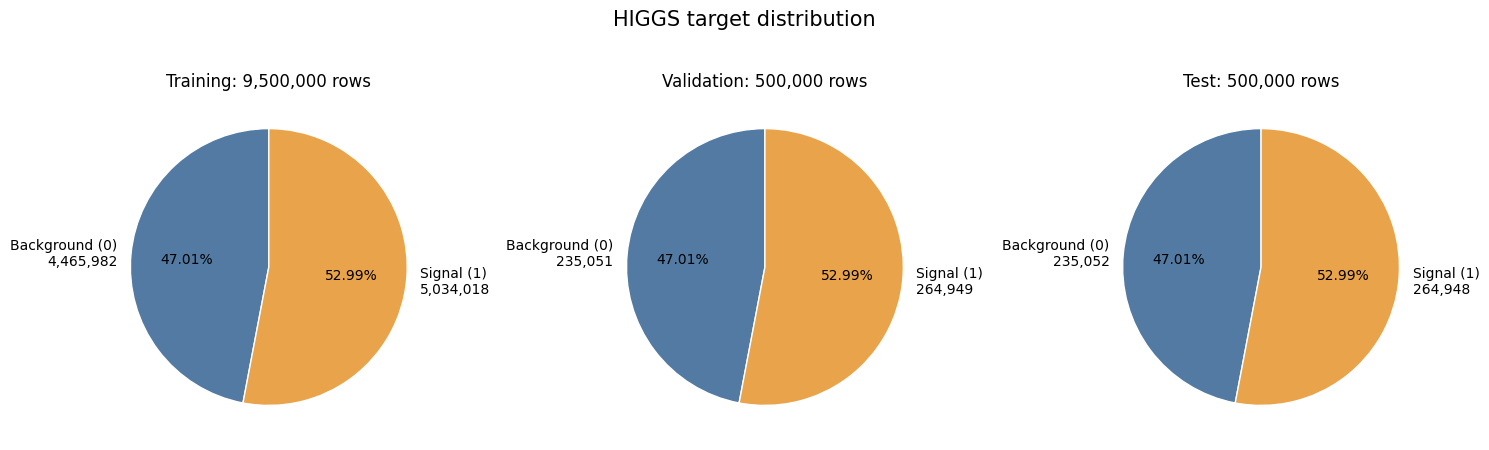

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, ids) in zip(
    axes,
    [
        ("Training", train_ids),
        ("Validation", valid_ids),
        ("Test", test_ids)
    ]
):
    counts = np.bincount(y_all[ids], minlength=2)

    ax.pie(
        counts,
        labels=[
            f"Background (0)\n{counts[0]:,}",
            f"Signal (1)\n{counts[1]:,}"
        ],
        autopct="%1.2f%%",
        colors=["#527AA3", "#E9A34B"],
        startangle=90,
        wedgeprops={"edgecolor": "white"}
    )

    ax.set_title(f"{name}: {len(ids):,} rows")

plt.suptitle("HIGGS target distribution", fontsize=15)
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "results" / "figures" / "target_distribution.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

In [9]:
X_all = np.load(
    PROCESSED_DIR / "X_all.npy",
    mmap_mode="r"
)

BATCH_SIZE = 100_000

for split_name, ids in [
    ("train", train_ids),
    ("valid", valid_ids),
    ("test", test_ids)
]:
    X_split = np.lib.format.open_memmap(
        PROCESSED_DIR / f"X_{split_name}.npy",
        mode="w+",
        dtype=np.float32,
        shape=(len(ids), X_all.shape[1])
    )

    y_split = np.lib.format.open_memmap(
        PROCESSED_DIR / f"y_{split_name}.npy",
        mode="w+",
        dtype=np.uint8,
        shape=(len(ids),)
    )

    for start in range(0, len(ids), BATCH_SIZE):
        end = min(start + BATCH_SIZE, len(ids))
        batch_ids = ids[start:end]

        X_split[start:end] = X_all[batch_ids]
        y_split[start:end] = y_all[batch_ids]

    X_split.flush()
    y_split.flush()

    print(
        f"{split_name}: "
        f"X {X_split.shape}, y {y_split.shape} saved",
        flush=True
    )

    del X_split, y_split

del X_all

train: X (9500000, 28), y (9500000,) saved
valid: X (500000, 28), y (500000,) saved
test: X (500000, 28), y (500000,) saved


In [10]:
import json

INPUT_INFO_DIR = PROJECT_DIR / "artifacts" / "input_info"

input_info = {
    "dataset": "HIGGS TFRecord shards",
    "source": "https://www.kaggle.com/datasets/ryanholbrook/higgs-boson",
    "total_rows": int(len(y_all)),
    "feature_columns": feature_columns,
    "feature_names_verified": False,
    "number_of_features": len(feature_columns),
    "feature_dtype": "float32",
    "target_dtype": "uint8",
    "target_labels": {
        "0": "Background",
        "1": "Signal"
    },
    "split_method": "Stratified random split across converted records",
    "random_state": RANDOM_STATE,
    "split_rows": {
        "train": len(train_ids),
        "valid": len(valid_ids),
        "test": len(test_ids)
    },
    "encoding": "None",
    "scaling": "None",
    "imputation": "None; non-finite values checked during conversion"
}

with open(INPUT_INFO_DIR / "higgs_input_info.json", "w") as file:
    json.dump(input_info, file, indent=2)

print("Preprocessing complete.")
print("Input information saved.")

del y_all, row_ids, remaining_ids
del train_ids, valid_ids, test_ids

Preprocessing complete.
Input information saved.
